# Sub-clustering and per-group pipelines

*Python port of the R vignette [Sub-clustering and per-group pipelines](https://gregorlueg.github.io/bixverse/articles/single_cell_subsets.html). Original author: Gregor Lueg.*

## Intro

Your first pass of clustering gives you lineages: T cells, B cells, monocytes.
What it does not give you is the structure inside those lineages. The highly
variable genes and the principal components were chosen to separate a monocyte
from a B cell, and on that axis every T cell looks the same. If you crank up the
Leiden resolution on the full object you mostly get the lineages chopped into
arbitrary pieces, not naive versus memory CD4.

The fix is to throw the global feature selection away and redo it on the cells
you actually care about. That is what `SingleCellsSubset` is for. It gives you a
view onto a subset of a `SingleCells` object that shares the on-disk counts
with the parent, but carries its own empty cache, so HVG, PCA, neighbours and
clusters all get recomputed from scratch on the subset alone.

This vignette assumes you have read the
[design choices](design_single_cell.ipynb) and the
[PBMC walkthrough](pbmc_single_cell.ipynb). The standard chain is not
re-explained here.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import NeighboursParams
from bixverse.pipeline import (
    Pipeline,
    apply_pipeline,
    apply_pipeline_per_group,
    step_clusters,
    step_hvg,
    step_neighbours,
    step_pca,
)

## A coarse first pass

Same PBMC3k data set as the main walkthrough, run through QC, HVG, PCA,
neighbours and Leiden without commentary.

In [2]:
pbmc3k_path = bv.io.download_pbmc3k()

tempdir_pbmc = tempfile.TemporaryDirectory()

sc = bv.io.load_mtx(
    Path(tempdir_pbmc.name) / "pbmc3k",
    bv.io.get_cell_ranger_params(pbmc3k_path),
)

sc.rename_var_col("column1", "gene_symbol")

var = sc.var()

ensembl_to_symbol = dict(zip(var["gene_id"], var["gene_symbol"], strict=True))
symbol_to_ensembl = dict(zip(var["gene_symbol"], var["gene_id"], strict=True))

Mitochondrial proportions, MAD outliers, cells to keep.

In [3]:
gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
}

bv.qc.gene_set_proportions(sc, gs_of_interest, streaming=False)

qc_df = sc.obs(cols=["cell_id", "lib_size", "nnz", "MT"])

qc = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
        "MT": qc_df["MT"].to_numpy(),
    },
    sc.cells_to_keep,
    directions={
        "log10_lib_size": "twosided",
        "log10_nnz": "twosided",
        "MT": "above",
    },
    threshold=3.0,
)

sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

Now the standard chain. The data is tiny, so exhaustive kNN beats building an
index.

In [4]:
bv.pp.find_hvg(sc, hvg_no=2000)

bv.pp.calculate_pca(sc, no_pcs=30, sparse_svd=True)

bv.graph.find_neighbours(
    sc, neighbours_params=NeighboursParams(knn_method="exhaustive")
)

bv.graph.find_clusters(sc, res=1.0, name="leiden_global")

bv.embed.umap(sc)

For the annotation we deliberately stay coarse. No CD4 versus CD8 split, no
naive versus memory. Lineage only, because the fine structure is exactly what
we want the subset to recover.

In [5]:
coarse_markers = {
    "CD3D": "T cells",
    "CD3E": "T cells",
    "CD3G": "T cells",
    "TRAC": "T cells",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD19": "B cells",
    "CD14": "Monocytes",
    "LYZ": "Monocytes",
    "S100A8": "Monocytes",
    "FCGR3A": "Monocytes",
    "GNLY": "NK",
    "NKG7": "NK",
    "KLRD1": "NK",
    "FCER1A": "DC",
    "CD1C": "DC",
    "LILRA4": "DC",
    "PPBP": "Platelet",
    "PF4": "Platelet",
}

coarse_df = pl.DataFrame(
    {"gene_symbol": list(coarse_markers), "cell_type": list(coarse_markers.values())}
).join(var.select("gene_symbol", "gene_id"), on="gene_symbol")

sctype_scores = bv.annotate.calc_sc_type_scores(
    sc, bv.annotate.prepare_cell_markers(sc, coarse_df)
)

obs = sc.obs(cols=["cell_idx", "leiden_global"], filtered=True)

cell_type_anno = bv.annotate.score_clusters(
    sctype_scores, obs["leiden_global"].to_numpy()
)

sc.add_obs(
    obs.join(
        cell_type_anno.select(pl.col("cluster_id").alias("leiden_global"), "cell_type"),
        on="leiden_global",
        how="left",
    ).select("cell_idx", "cell_type")
)

sc.obs(filtered=True)["cell_type"].value_counts(sort=True)

cell_type,count
str,u32
"""T cells""",1130
"""Monocytes""",599
"""NK""",423
"""B cells""",314
"""DC""",24


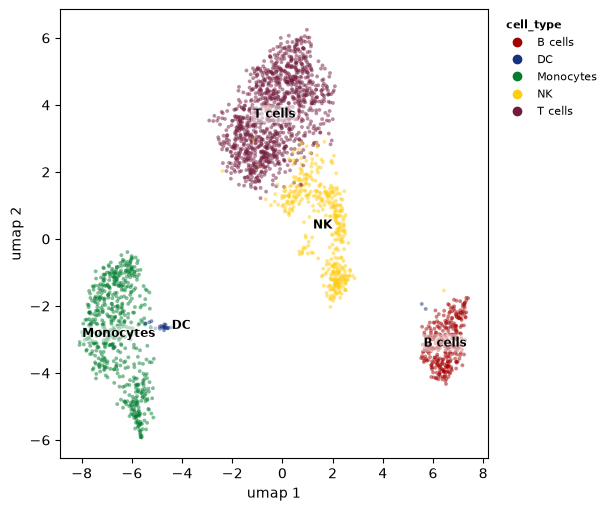

In [6]:
bv.pl.embedding_plot(sc, "umap", "cell_type", label_by="cell_type", discrete=True)
plt.show()

## Taking a subset

The constructor takes the parent, a column in obs, and the level you want.

In [7]:
t_cells = bv.SingleCellsSubset(sc, "cell_type", "T cells")

t_cells

SingleCellsSubset(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpqyydgzjo/pbmc3k',
  group=cell_type = T cells,
  cells=1130, genes=11139,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

The repr tells you the important bit: HVG, PCA, kNN and the graph are all
`False`. Nothing was inherited. The subset reads the parent's stores, so no
counts were copied and no files were written, but the `ScCache` is brand new
and the parent's HVG selection was dropped on purpose.

Everything else behaves like the parent object. The obs table is filtered to
the group and held in memory, the var table is untouched, and the usual
getters work.

In [8]:
t_cells.shape

(1130, 11139)

In [9]:
t_cells.obs(cols=["cell_id", "cell_idx", "lib_size", "cell_type"]).head()

cell_id,cell_idx,lib_size,cell_type
str,u32,f64,str
"""AAACATACAACCAC-1""",0,2418.0,"""T cells"""
"""AAACATTGATCAGC-1""",2,3144.0,"""T cells"""
"""AAACGCACTGGTAC-1""",5,2154.0,"""T cells"""
"""AAACTTGATCCAGA-1""",11,2382.0,"""T cells"""
"""AAAGAGACGAGATA-1""",12,2403.0,"""T cells"""


### A note on indices

This is the one place where you can shoot yourself in the foot, so it is worth
being explicit. In Python there is a single cell index space: the 0-based
position in the parent's stores. `cell_idx` in the subset's obs,
`subset_to_original`, `cells_to_keep` and every integer selection you hand to
a getter live in it. Integer selections must belong to the subset, and cell
ids are matched against the subset's cells only. The one exception is
`obs(indices=...)`, which takes row positions within the subset's own obs
table.

`cell_indices()` maps ids to that space.

In [10]:
first_three = t_cells.cell_ids()[:3]

# 0-based position in the parent's stores, which is what Rust sees
t_cells.cell_indices(list(first_three))

array([0, 2, 5], dtype=uint32)

In [11]:
assert np.array_equal(
    t_cells.cell_indices(list(first_three)), t_cells.subset_to_original[:3]
)

The practical upshot: you never translate manually. Hand cell ids or store
indices to the getters and let the class deal with it. The `cell_idx` column
is there so you can join results back onto the parent later, which is exactly
what we do further down.

## Re-running the chain

Same functions as on the parent. They take the subset just the same.

In [12]:
bv.pp.find_hvg(t_cells, hvg_no=2000)

bv.pp.calculate_pca(t_cells, no_pcs=20, sparse_svd=True)

bv.graph.find_neighbours(
    t_cells, neighbours_params=NeighboursParams(knn_method="exhaustive")
)

bv.graph.find_clusters(t_cells, res=0.5, name="t_subcluster")

bv.embed.umap(t_cells)

t_cells

SingleCellsSubset(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpqyydgzjo/pbmc3k',
  group=cell_type = T cells,
  cells=1130, genes=11139,
  hvg=True, pca=True, embeddings=['umap'],
  knn=True, graph=True, magic=False, residuals=False,
  stale=none
)

Was any of that worth it? Check how much the feature selection actually moved.

In [13]:
global_hvg = sc.map.hvg
subset_hvg = t_cells.map.hvg

len(np.intersect1d(global_hvg, subset_hvg))

984

Around a thousand of the 2000 genes are different, and the ones that dropped out
are the monocyte and B cell markers that were carrying the global PCA. The
subset PCA is built on genes that vary *within* T cells, which is the whole
point.

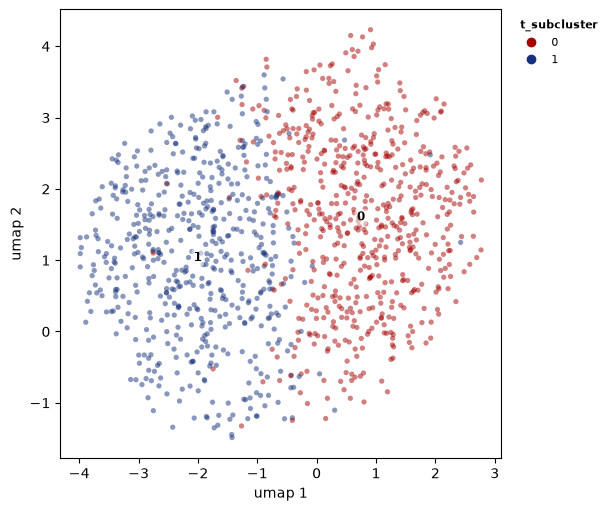

In [14]:
bv.pl.embedding_plot(
    t_cells, "umap", "t_subcluster", label_by="t_subcluster", discrete=True
)
plt.show()

## Markers for the sub-clusters

Differential expression on the subset is confined to it. Each sub-cluster is
tested against the other T sub-clusters, not against every monocyte in the
data set.

In [15]:
sub_markers = bv.de.find_all_markers(t_cells, "t_subcluster").with_columns(
    pl.col("gene_id").replace_strict(ensembl_to_symbol).alias("gene_symbol")
)

(
    sub_markers.filter(pl.col("fdr") <= 0.05)
    .sort(["grp", "lfc"], descending=[False, True])
    .group_by("grp", maintain_order=True)
    .head(5)
    .select("grp", "gene_symbol", "lfc", "fdr")
)

grp,gene_symbol,lfc,fdr
i32,str,f64,f64
0,"""S100A4""",1.597716,1.5215e-100
0,"""ANXA1""",0.906684,2.1903e-36
0,"""S100A10""",0.843058,3.6921e-33
0,"""S100A11""",0.825352,3.4953e-38
0,"""IL32""",0.8152,6.1423e-36
1,"""CCR7""",0.602159,8.0570e-25
1,"""CD8B""",0.429373,4.1373e-14
1,"""C6orf48""",0.386663,1.2145e-10
1,"""MALAT1""",0.336235,1.8883e-44


S100A4, ANXA1 and IL32 on one side, CCR7 and CD8B on the other. That is
the memory versus naive split, and the global clustering had no way of seeing
it.

The expression plots work on the subset too, so you can go straight to a dot
plot without touching the parent.

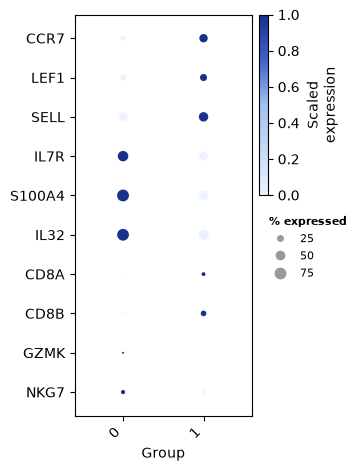

In [16]:
t_features = [
    symbol_to_ensembl[s]
    for s in (
        "CCR7",
        "LEF1",
        "SELL",
        "IL7R",
        "S100A4",
        "IL32",
        "CD8A",
        "CD8B",
        "GZMK",
        "NKG7",
    )
    if s in symbol_to_ensembl
]

bv.pl.dot_plot(
    t_cells,
    t_features,
    "t_subcluster",
    feature_labels={f: ensembl_to_symbol[f] for f in t_features},
    scale_exp=True,
    cluster_groups=True,
)
plt.show()

## Getting the labels back to the parent

So far everything lives in the subset, in memory. To make the labels permanent,
or to plot them on the parent's global UMAP, push them into the parent's DuckDB.
`merge_subset_obs()` does the join on `cell_idx` for you.

In [17]:
bv.merge_subset_obs(sc, t_cells, cols=["t_subcluster"], prefix_values=True)

sc.obs(filtered=True)["t_subcluster"].value_counts().sort("t_subcluster")

t_subcluster,count
str,u32
null,1360
"""T cells_0""",587
"""T cells_1""",543


`prefix_values=True` stamps the subset's group onto every value, so you get
`T cells_0` rather than a bare `0`. Drop it if you want the raw labels. Leave
`cols` out and everything the subset gained that the parent does not have yet
gets merged, which after a pipeline run is exactly the new columns.

The join is a left join, so every cell that was not a T cell gets `null`. That
is the behaviour you want, and the downstream methods respect it.

Results that already carry their own `cell_idx` skip the helper entirely.
`fast_cluster()` returns memberships keyed in parent space, so `add_obs()`
takes them directly.

In [18]:
fast_sub = bv.graph.fast_cluster(t_cells, resolutions=(1.0, 0.5))

sc.add_obs(fast_sub.memberships)

sc.obs(filtered=True).select(
    "cell_id", "cell_type", "t_subcluster", *fast_sub.memberships.columns[1:]
).head()

cell_id,cell_type,t_subcluster,res_1,res_0.5
str,str,str,i32,i32
"""AAACATACAACCAC-1""","""T cells""","""T cells_0""",0,0
"""AAACATTGAGCTAC-1""","""B cells""",null,null,null
"""AAACATTGATCAGC-1""","""T cells""","""T cells_0""",0,0
"""AAACCGTGCTTCCG-1""","""Monocytes""",null,null,null
"""AAACCGTGTATGCG-1""","""NK""",null,null,null


## Pipelines

Once you are doing this for more than one cell type, writing out HVG, PCA,
neighbours and clusters by hand five times gets old. A `Pipeline` lets you
declare the chain once. Steps chain with `>>`.

In [19]:
subcluster_pipeline = (
    step_hvg(hvg_no=2000)
    >> step_pca(no_pcs=20, sparse_svd=True)
    >> step_neighbours(neighbours_params=NeighboursParams(knn_method="exhaustive"))
    >> step_clusters(res=0.5, name="subcluster")
)

subcluster_pipeline

<Pipeline> 4 steps
  1. hvg         hvg_no=2000, hvg_params=None, streaming=None, verbose=False
  2. pca         no_pcs=20, pca_params=None, sparse_svd=True, hvg=None, seed=42, residuals=False, verbose=False
  3. neighbours  embd_to_use='pca', no_embd_to_use=None, modality='rna', neighbours_params=<NeighboursParams>, seed=42, verbose=False
  4. clusters    cluster_algorithm='leiden', res=0.5, name='subcluster', modality='rna', seed=42, beta=0.01, n_iterations=None, min_gain=0.0, local_moving='queue'

If you prefer, `Pipeline` takes a plain list of steps too.

In [20]:
assert Pipeline(list(subcluster_pipeline.steps)) == subcluster_pipeline

Pipelines are inert. Nothing runs until you apply one, and the same pipeline
works on a `SingleCells` or a `SingleCellsSubset`, because each step's function
takes either.

In [21]:
b_cells = bv.SingleCellsSubset(sc, "cell_type", "B cells")

b_cells = apply_pipeline(subcluster_pipeline, b_cells)

b_cells

SingleCellsSubset(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpqyydgzjo/pbmc3k',
  group=cell_type = B cells,
  cells=314, genes=11139,
  hvg=True, pca=True, embeddings=none,
  knn=True, graph=True, magic=False, residuals=False,
  stale=none
)

### One pipeline, every group

`apply_pipeline_per_group()` builds the subset for you and returns a dict keyed
by group.

Sizing matters here. PCA with 20 components needs more than 20 cells, so a rare
population that the annotation happened to call will fall over and take the
whole run with it. Restrict the groups explicitly rather than hoping for the
best. On this data set the coarse annotation returned five lineages, and the
24 DCs don't clear the bar, so they stay out.

In [22]:
cell_counts = sc.obs(filtered=True)["cell_type"].value_counts(sort=True)

groups_to_run = cell_counts.filter(pl.col("count") >= 100)["cell_type"].to_list()

groups_to_run

['T cells', 'Monocytes', 'NK', 'B cells']

In [23]:
per_group = apply_pipeline_per_group(
    subcluster_pipeline, sc, "cell_type", groups=groups_to_run
)

pl.DataFrame(
    [
        {
            "cell_type": name,
            "n_cells": x.shape[0],
            "n_subclusters": x.obs()["subcluster"].n_unique(),
            "hvg_shared_with_global": len(np.intersect1d(x.map.hvg, global_hvg)),
        }
        for name, x in per_group.items()
    ]
).sort("n_cells", descending=True)

cell_type,n_cells,n_subclusters,hvg_shared_with_global
str,i64,i64,i64
"""T cells""",1130,2,984
"""Monocytes""",599,2,856
"""NK""",423,2,660
"""B cells""",314,1,569


Every lineage picked a different feature set, and the shared fraction with the
global HVGs is nowhere near complete. Running one global PCA and hoping it
resolves everything was never going to work.

Writing all of that back is one call. `merge_subset_obs()` takes the values of
the dict straight from `apply_pipeline_per_group()`, checks that no cell shows
up twice, and does a single join.

In [24]:
bv.merge_subset_obs(
    sc,
    list(per_group.values()),
    cols=["subcluster"],
    new_names=["fine_label"],
    prefix_values=True,
)

sc.obs(filtered=True)["fine_label"].value_counts().sort("fine_label")

fine_label,count
str,u32
null,24
"""B cells_0""",314
"""Monocytes_0""",360
"""Monocytes_1""",239
"""NK_0""",271
"""NK_1""",152
"""T cells_0""",587
"""T cells_1""",543


The prefix is doing real work here. Every group's Leiden run starts counting at
zero, so without it the T cell `1` and the B cell `1` collapse into one label.
Leave it out and you get a warning naming the values that clash. The DCs never
went through the pipeline, so they are the `null` row.

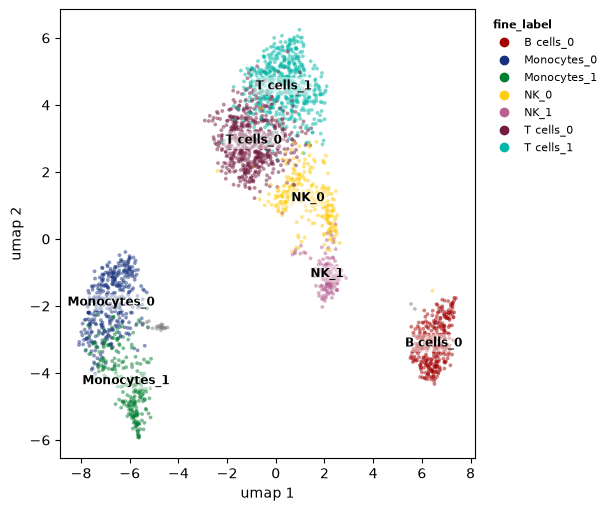

In [25]:
bv.pl.embedding_plot(sc, "umap", "fine_label", label_by="fine_label", discrete=True)
plt.show()

## Source-pure meta cells

All three meta cell generators run on a subset, so you can aggregate per
patient and never mix two donors into one meta cell. The catch used to be the
last step: you ended up with one `MetaCells` object per patient and no way to
run SCENIC or NMF across the lot. `bv.metacells.merge_meta_cells()` closes
that.

`step_metacells()` puts the generation into the chain itself. It is the one
step that changes the class of the object, so a pipeline that ends on it hands
you `MetaCells` rather than `SingleCellsSubset`. Everything before it still runs
per patient, which is the point when your samples are split over two plates and
need correcting within a donor.

```python
from bixverse.params import BtMetacellsParams
from bixverse.pipeline import step_harmony, step_metacells

mc_pipeline = (
    step_hvg(hvg_no=2000)
    >> step_pca(no_pcs=20)
    >> step_harmony(batch_column="plate")
    >> step_neighbours(embd_to_use="harmony")
    >> step_metacells(
        "bootstrapped", params=BtMetacellsParams(target_no_metacells=100)
    )
)

per_patient = apply_pipeline_per_group(mc_pipeline, sc, "patient_id")

meta_cells = bv.metacells.merge_meta_cells(per_patient)
```

A few things worth knowing:

- `bv.metacells.meta_cells_per_group()` does the whole thing in one call if
  you do not need the per-patient objects. Same arguments, plus `method` and
  `mc_params`.
- The merged obs table gains a `source_id` column and the meta cell ids are
  prefixed with it. `original_cell_idx` stays in the index space of its own
  source, so it is only meaningful alongside `source_id`.
- Gene spaces are reconciled by `"intersect"` (the default) or `"union"`, the
  latter zero-filling genes an input lacks. Both are no-ops when every input
  came from the same parent object.
- Counts are carried over untouched. Normalisation is per meta cell, so
  row-binding leaves it valid.
- PCA, kNN, sNN and HVG are dropped on merge. They were fitted per patient and
  mean nothing side by side. Recompute them on the merged object, which is the
  whole reason for merging.
- `validate_pipeline()` checks a chain against a starting class before anything
  runs. `apply_pipeline()` and `apply_pipeline_per_group()` call it for you, so
  putting `step_harmony()` after `step_metacells()` errors immediately instead
  of after twenty minutes of PCA.

## Caveats and what is next

A few sharp edges to be aware of before you build on this.

Meta cell memberships come back as positions in the *parent's* stores, which
is what makes them joinable back onto the original object.
`bv.de.get_pseudobulked()` runs on subsets too if aggregation is all you are
after.

Subsets are RNA only, so multi-modal work stays on `SingleCellsMultiModal`
(see the [multi-modal vignette](multi_modal_single_cells.ipynb)).

Subsets nest conceptually but not in code: you cannot build a
`SingleCellsSubset` from another `SingleCellsSubset`. If you want a third level,
write the labels back to the parent and subset from there.

## Clean up

In [26]:
tempdir_pbmc.cleanup()